# Joint HPP–DC lifetime financial sizing

Native Parallel EGO maximizes one selected financial metric minus the rational reliability search penalty. Final selection requires independently validated physical dispatch and reliability. All monetary results exclude the search penalty. The default is NPV / discounted lifetime CAPEX; initial-CAPEX NPV/CAPEX remains a separate indicator.


In [ ]:
from pathlib import Path
from copy import deepcopy
import pandas as pd
import json
from IPython.display import display, Image
from hydesign.sizing_native_joint_hpp_dc_sizing import (
    ROOT, read_configuration, prepare_configuration, run_native_joint_hpp_dc_sizing,
    run_joint_revenue_scenarios, load_joint_hpp_dc_sizing, load_joint_revenue_scenarios,
    run_joint_penalty_scenarios, load_joint_penalty_scenarios)
from hydesign.assembly.hpp_assembly_simple_datacenter_joint_hpp_dc_sizing import IT_NAME
from hydesign.finance.finance_simple_datacenter import SCALAR_OUTPUTS

# Configuration: YAML defaults, with optional overrides here.
config_path = ROOT / 'hydesign/examples/thesis_simple_datacenter/simple_datacenter.yml'
defaults = prepare_configuration(config_path, read_configuration(config_path))
objective = 'NPV_over_PV_CAPEX_system'  # NPV_over_PV_CAPEX_system / NPV_system / net_annual_value_system
revenue_scenarios = [800]
penalty_epsilons = [0.008, 0.01, 0.02033, 0.03388, 0.1]
pue = 1.15
outer_time_budget = 60 * 90
financial_overrides = {}  # e.g. {'tax_rate': 0.22}; all existing finance assumptions are configurable.

# Same native variable dictionary and HPP bounds as the existing joint notebook.
variables = deepcopy(defaults['variables'])
for name in ('Nwt', 'solar_MW [MW AC]', 'b_P [MW]', 'b_E_h [h]'):
    variables[name]['var_type'] = 'design'  # Edit 'limits' here if needed.
variables['Nwt']['limits'] = [5, 60]
variables['solar_MW [MW AC]']['limits'] = [50, 250]
variables['b_P [MW]']['limits'] = [10, 80]
variables['b_E_h [h]']['limits'] = [2, 15]
variables[IT_NAME] = dict(var_type='design', types='float', value=16/pue, limits=[15/pue, 35/pue])

config = dict(defaults,
    variables=variables, joint_sizing_objective=objective,
    datacenter_firm_revenue_per_mwh_it=revenue_scenarios[0],
    reliability_target=0.999, pue=pue,
    project_discount_rate=defaults['project_discount_rate'],
    joint_reference_pv_capex_eur=defaults['joint_reference_pv_capex_eur'],
    joint_penalty_scaling='reference_revenue', joint_penalty_mode='rational',
    joint_penalty_gamma=0.25,
    joint_penalty_A=2.0,
    joint_penalty_lambda=1e-9,
    joint_penalty_epsilon=penalty_epsilons[0],
    hpp_sizing_time_limit_seconds=outer_time_budget,
    ems_time_limit_seconds=defaults['ems_time_limit_seconds'], ems_threads=defaults['ems_threads'],
    n_procs=2, n_doe=16,
    n_clusters=2, npred=10000, n_seed=1,
    max_iter=defaults['max_iter'], tol=defaults['tol'], min_conv_iter=defaults['min_conv_iter'],
    hpp_sizing_output_dir=str(ROOT / 'hpp_sizing_runs/joint_hpp_dc_sizing'),
)
config.update(financial_overrides)
run_mode = 'penalty_batch'  # 'single', 'revenue_batch', 'penalty_batch', or 'load'
saved_run = None     # Existing run directory for 'load'; never starts EMS/EGO.
saved_batch = None   # Existing revenue/penalty batch directory for 'load'.
regenerate_saved_figures = False

print('Objective:', config['joint_sizing_objective'], '| reliability:', config['reliability_target'],
      '| IT revenue [EUR/MWh]:', config['datacenter_firm_revenue_per_mwh_it'])


Objective: NPV_over_PV_CAPEX_system | reliability: 0.999 | IT revenue [EUR/MWh]: 800


## Run or load

The search deadline includes startup and DOE. Recovery and plotting have their existing separate deadlines. Each new run/batch gets a unique timestamped directory. Loading uses saved financial assumptions, not the current YAML.

Penalty batch: six independent 30-minute searches at EUR 800/MWh IT. Only epsilon changes; bounds, seed, DOE, finance and solver settings stay fixed. Lambda = 1e-9 makes the penalty approximately S * epsilon * excess failed hours. The summary saves the actual scale, exact one-hour penalty, and linear slope. No full batch runs until you execute the run cell.


In [2]:
batch_directory = None
run_directory = None
if run_mode == 'single':
    result = run_native_joint_hpp_dc_sizing(config_path, config)
    run_directory = Path(result['run_directory'])
elif run_mode in ('revenue_batch', 'penalty_batch'):
    if run_mode == 'penalty_batch':
        if revenue_scenarios != [800]:
            raise ValueError('The penalty batch requires revenue_scenarios = [800].')
        batch_directory, summary = run_joint_penalty_scenarios(config_path, config, penalty_epsilons)
    else:
        batch_directory, summary = run_joint_revenue_scenarios(config_path, config, revenue_scenarios)
    display(summary)
    completed = summary.run_directory.dropna()
    if not completed.empty:
        run_directory = Path(completed.iloc[-1])
elif run_mode == 'load':
    if saved_batch is not None:
        batch_directory = Path(saved_batch)
        manifest = json.loads((batch_directory / 'configuration.json').read_text())
        loader = (load_joint_penalty_scenarios if manifest.get('batch_kind') == 'penalty'
                  else load_joint_revenue_scenarios)
        summary = loader(batch_directory, save_figures=regenerate_saved_figures)
        display(summary)
        completed = summary.run_directory.dropna()
        if not completed.empty:
            run_directory = Path(completed.iloc[-1])
    if saved_run is not None:
        run_directory = Path(saved_run)
    if saved_batch is None and saved_run is None:
        raise ValueError('Set saved_run or saved_batch to inspect saved results.')
else:
    raise ValueError('Choose single, revenue_batch, penalty_batch, or load.')

result, history = {}, pd.DataFrame()
if batch_directory is not None:
    print('Batch summary:', batch_directory / 'summary.csv')
if run_directory is not None:
    result, history = load_joint_hpp_dc_sizing(run_directory, save_figures=regenerate_saved_figures)
    print('Saved results:', run_directory)
    print('Status:', result['final_status'])
    print('Evaluations:', result.get('evaluated_designs'), '| feasible:', result.get('feasible_evaluations'))


Penalty batch: C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\penalty_batch_20261125_223007Z_8244b4a3
Penalty epsilon: 0.008
Joint HPP-DC results: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\penalty_batch_20261125_223007Z_8244b4a3\epsilon_0p008\20261125_223009Z_4db0b4a1_joint_hpp_dc_sizing
Penalty epsilon: 0.01
Joint HPP-DC results: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\penalty_batch_20261125_223007Z_8244b4a3\epsilon_0p01\20261126_000038Z_68390a4e_joint_hpp_dc_sizing
Penalty epsilon: 0.02033
Joint HPP-DC results: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\penalty_batch_20261125_223007Z_8244b4a3\epsilon_0p02033\20261126_013116Z_41895239_joint_hpp_dc_sizing
Penalty epsilon: 0.03388
Joint HPP-DC results: \\?\C:\Users\loic

,scenario_index,revenue_eur_per_mwh_it,status,run_directory,evaluations_csv,error,evaluations,feasible_evaluations,search_seconds,total_seconds,...,annualized_cost_hpp,annualized_cost_dc,net_annual_value_system,served_it_energy_mwh,served_facility_energy_mwh,reliability_penalty_eur_per_year,penalized_annual_value,unpenalized_objective,penalized_objective,reliability_penalty
0,1,800,VALIDATED_FEASIBLE_INCUMBENT,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,NaN,398,46,5400.000608,5427.011016,...,3.185206e+07,1.351528e+08,2.610722e+07,241390.130462,277598.650032,0.0,2.610722e+07,0.168123,0.168123,0.0
1,2,800,VALIDATED_FEASIBLE_INCUMBENT,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,NaN,427,89,5400.000450,5436.089960,...,3.002187e+07,1.300630e+08,2.576120e+07,232307.620587,267153.763675,0.0,2.576120e+07,0.173327,0.173327,0.0
2,3,800,RECOVERY_INCOMPLETE,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,NaN,463,203,5400.000207,5464.272038,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,800,VALIDATED_FEASIBLE_INCUMBENT,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,TypeError: '<' not supported between instances...,87,44,913.160563,936.394733,...,2.591233e+07,1.125463e+08,2.235193e+07,201013.182116,231165.159433,0.0,2.235193e+07,0.173924,0.173924,0.0
4,5,800,RECOVERY_INCOMPLETE,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,\\?\C:\Users\loict\OneDrive\Skrivebord\Master ...,NaN,460,221,5400.000000,5464.261645,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Batch summary: C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\penalty_batch_20261125_223007Z_8244b4a3\summary.csv
Saved results: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\penalty_batch_20261125_223007Z_8244b4a3\epsilon_0p1\20261126_031800Z_43c988ce_joint_hpp_dc_sizing
Status: RECOVERY_INCOMPLETE
Evaluations: 460 | feasible: 221


## Best validated design and financial results

Only reliability-feasible designs qualify. IRR is a fraction (multiply by 100 for percent); money is EUR, annual flows EUR/year and payback years. Undefined indicators are blank. A time-limited incumbent is not proof of a global optimum.


In [3]:
best = result.get('best')
if best:
    d, e, m, s = (best[k] for k in ('design', 'economics', 'metrics', 'scoring'))
    display(pd.DataFrame([{
        'Objective': best.get('objective', 'net_annual_value_system'),
        'Unpenalized objective': s.get('unpenalized_objective', e['net_annual_value_system']),
        'Search penalty': s.get('reliability_penalty', s['reliability_penalty_eur_per_year']),
        'Penalized objective': s.get('penalized_objective', s['penalized_annual_value']),
        'Wind [MW]': d[2]*d[3], 'Nwt': d[3], 'PV [MW AC]': d[5],
        'Battery [MW]': d[9], 'Battery [MWh]': d[9]*d[10],
        'IT [MW]': d[-1], 'Facility [MW]': e['facility_load_mw'],
        'Reliability [%]': 100*m['firm_reliability'], 'LOLH [h]': m['LOLH'],
        'Physical validation': best['physical_validation_passed'],
    }]))
    display(pd.Series(e, name='Financial result').reindex(list(SCALAR_OUTPUTS) + [
        'annualized_cost_hpp', 'annualized_cost_dc', 'net_annual_value_system']))
    display(pd.Series(best.get('penalty_scales', {}), name='Saved penalty calibration'))
    for filename in ('cost_breakdown.csv', 'cashflows.csv'):
        path = run_directory / filename
        if path.exists():
            print(filename)
            display(pd.read_csv(path))
else:
    print('No validated feasible solution found. Inspect candidate history and solver statuses.')
display(history.tail())


No validated feasible solution found. Inspect candidate history and solver statuses.


,evaluation_index,elapsed_seconds,status,accepted,Nwt,wind_MW,solar_MW,b_P,b_E_h,b_E,...,reference_revenue_pv_eur,reference_capex_pv_eur,npv_penalty_scale_eur,objective_penalty_scale,reference_capex_method,financial_penalty_scaling,solver_status,solver,validation,bounds
455,456,5316.645376,BELOW_TARGET,False,30.0,150.0,118.796813,69.12764,14.797535,1022.918659,...,2.485557e+09,2.105607e+09,3.106947e+08,0.147556,upper_design_bounds,reference_revenue_pv,"{""backend"": ""cplex"", ""optimal"": true, ""feasibl...","[{""status_code"": 101, ""status"": ""integer optim...","{""metrics"": {""LOLH"": 15.0, ""firm_reliability"":...","{""cost_upper_bound_eur_per_year"": 196349727.43..."
456,457,5338.448839,FEASIBLE,True,30.0,150.0,134.925451,69.12764,14.797535,1022.918659,...,2.485557e+09,2.105607e+09,3.106947e+08,0.147556,upper_design_bounds,reference_revenue_pv,"{""backend"": ""cplex"", ""optimal"": true, ""feasibl...","[{""status_code"": 101, ""status"": ""integer optim...","{""metrics"": {""LOLH"": 8.0, ""firm_reliability"": ...","{""cost_upper_bound_eur_per_year"": 196349727.43..."
457,458,5344.757904,FEASIBLE,True,34.0,170.0,118.796813,69.12764,14.797535,1022.918659,...,2.485557e+09,2.105607e+09,3.106947e+08,0.147556,upper_design_bounds,reference_revenue_pv,"{""backend"": ""cplex"", ""optimal"": true, ""feasibl...","[{""status_code"": 101, ""status"": ""integer optim...","{""metrics"": {""LOLH"": 7.0, ""firm_reliability"": ...","{""cost_upper_bound_eur_per_year"": 196349727.43..."
458,459,5351.861543,FEASIBLE,True,30.0,150.0,118.796813,69.12764,15.000000,1036.914598,...,2.485557e+09,2.105607e+09,3.106947e+08,0.147556,upper_design_bounds,reference_revenue_pv,"{""backend"": ""cplex"", ""optimal"": false, ""feasib...","[{""status_code"": 107, ""status"": ""time limit ex...","{""metrics"": {""LOLH"": 8.0, ""firm_reliability"": ...","{""cost_upper_bound_eur_per_year"": 196349727.43..."
459,460,5379.847219,BELOW_TARGET,False,46.0,230.0,56.670000,74.31950,2.194350,163.082995,...,2.485557e+09,2.105607e+09,3.106947e+08,0.147556,upper_design_bounds,reference_revenue_pv,"{""backend"": ""cplex"", ""optimal"": false, ""feasib...","[{""status_code"": 107, ""status"": ""time limit ex...","{""metrics"": {""LOLH"": 104.0, ""firm_reliability""...","{""cost_upper_bound_eur_per_year"": 196349727.43..."


## Saved figures

Discounted lifetime CAPEX includes phased initial purchases and scheduled battery/IT replacements, with the same inflation and discounting as NPV. The fixed penalty reference defaults to discounted CAPEX at the upper design bounds; it can be overridden in EUR. Unlike a candidate-specific denominator, it does not reduce the failed-hour penalty as a candidate gets more expensive. This finite search penalty does not guarantee feasible-first EGO rankings; final feasibility remains mandatory.

For excess failed hours v = max(0, LOLH - floor((1 - target)*8760)), the lifetime penalty is:

- Reference revenue PV = sum of (maximum IT MW * 8760 * IT revenue rate * revenue inflation index) discounted over operating years 1..T.
- NPV penalty = (gamma * reference revenue PV / A) * [A * lambda * v / (A + lambda * v) + epsilon * v].
- Ratio penalty = NPV penalty / fixed reference discounted CAPEX.
- Ratio EGO objective = candidate NPV / candidate discounted lifetime CAPEX - ratio penalty.

Annual-value mode retains its existing annual monetary penalty. YAML lists the runner's existing penalty defaults; the older revenue-sensitivity notebook's explicit lambda=0.20 override can be entered in the configuration cell for matched comparisons. No calibration parameters are changed automatically when choosing an objective.


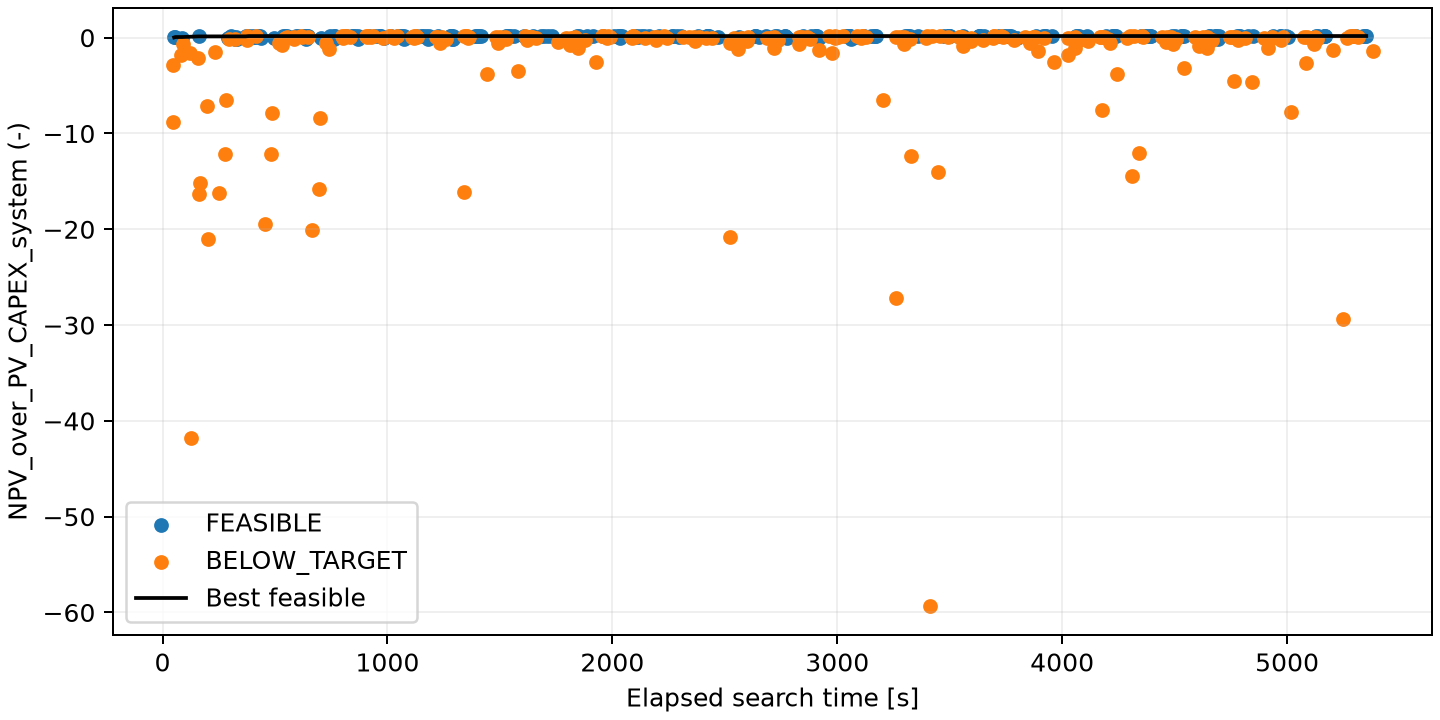

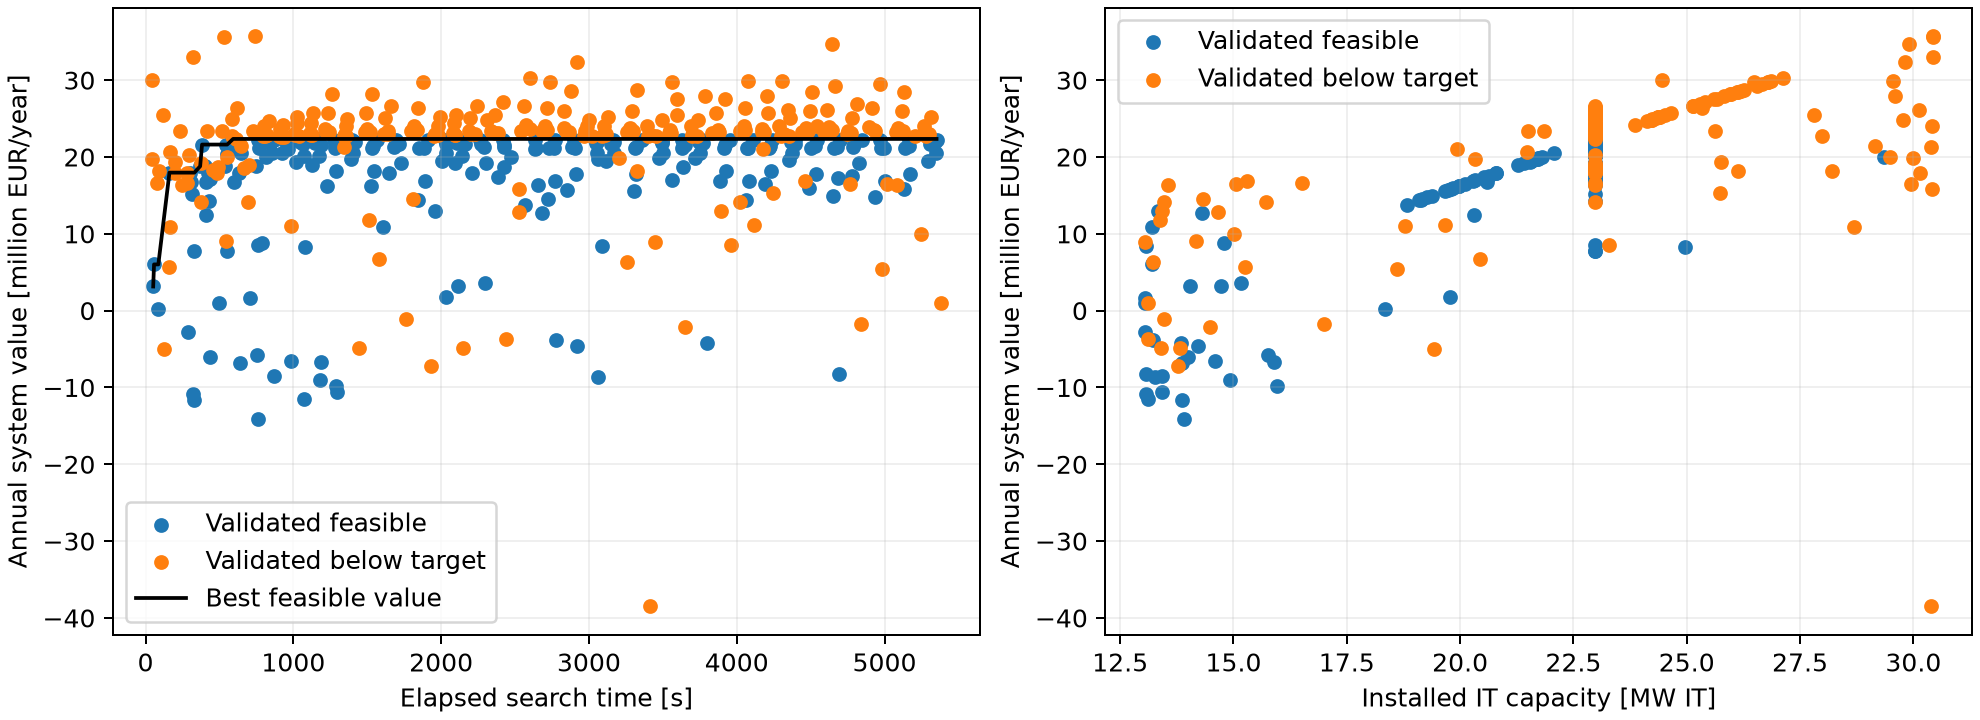

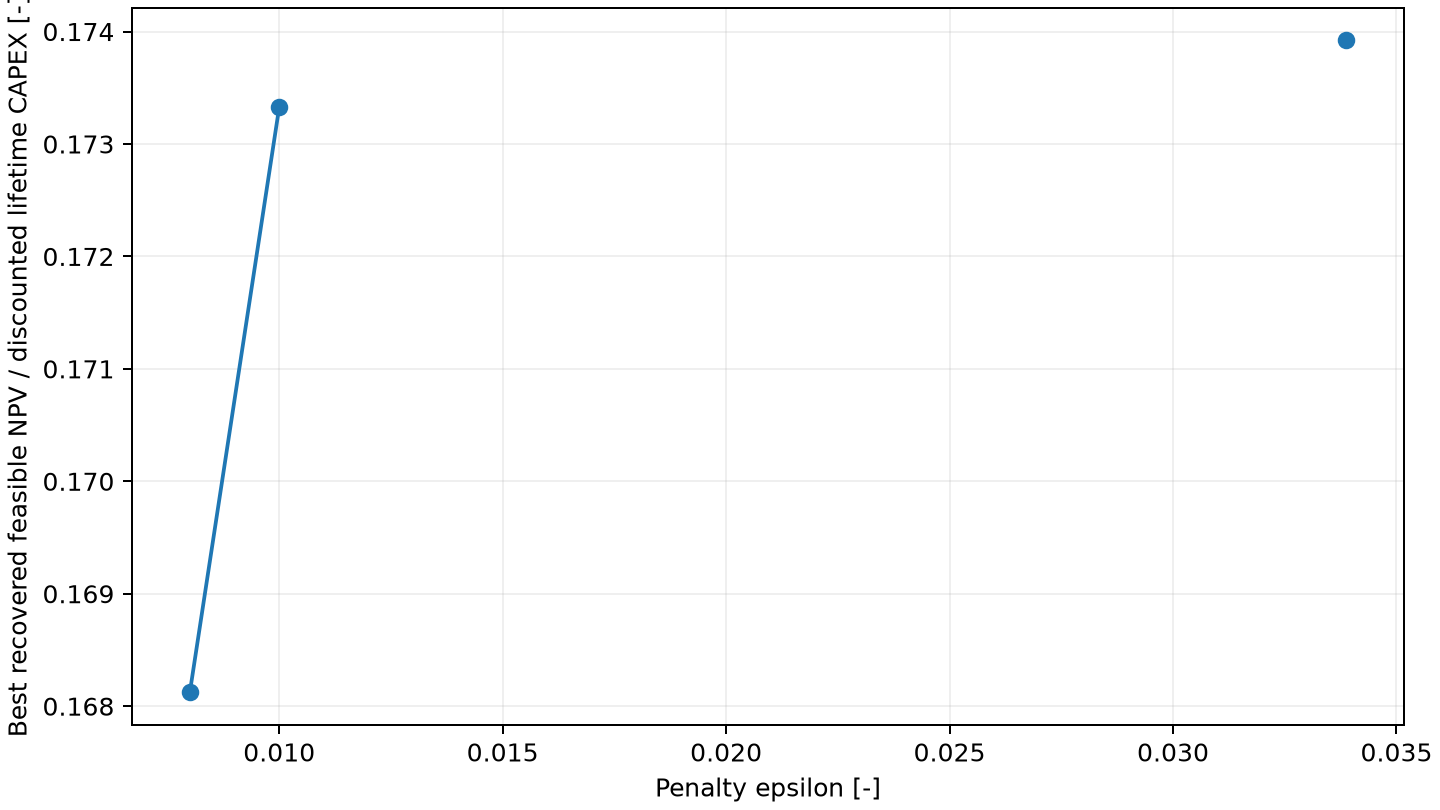

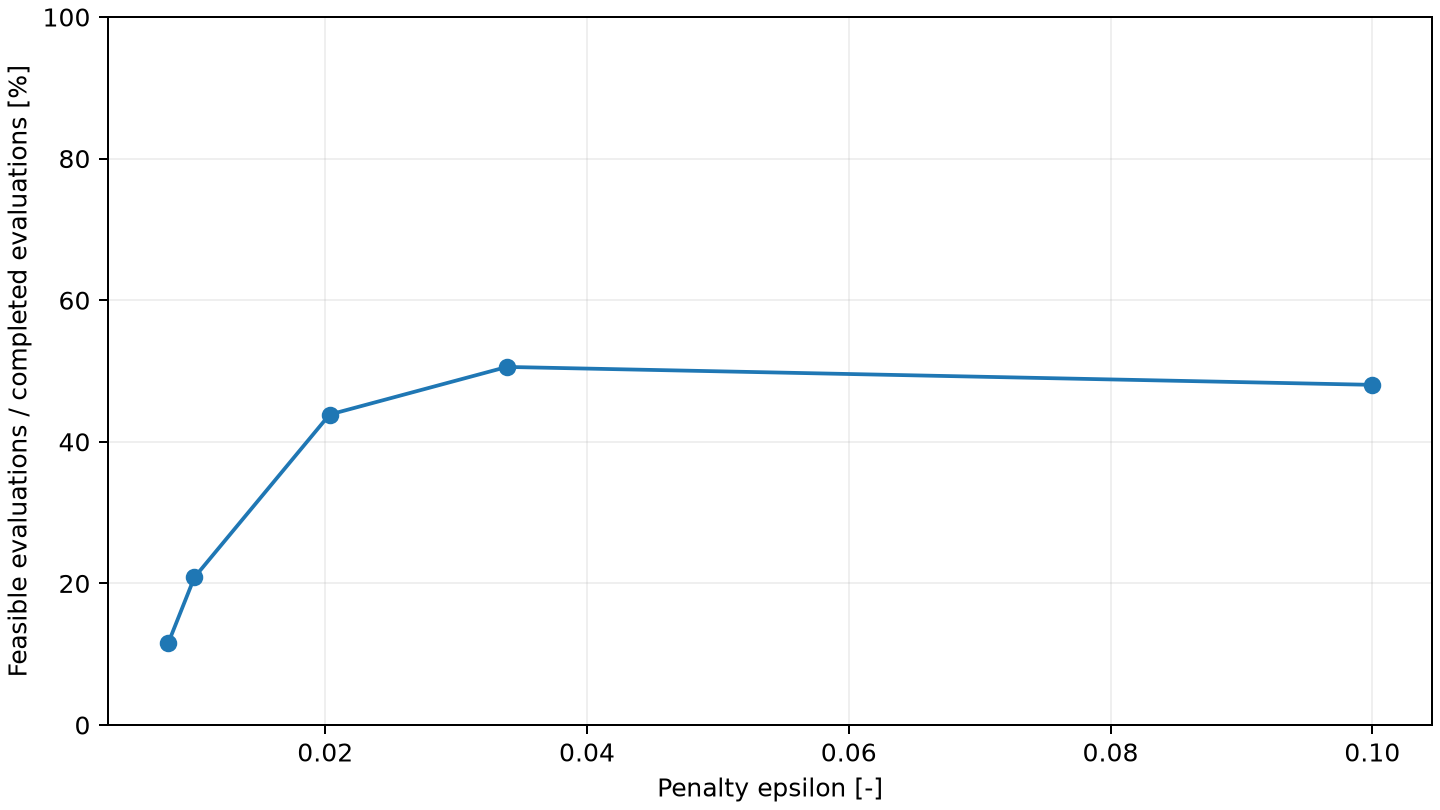

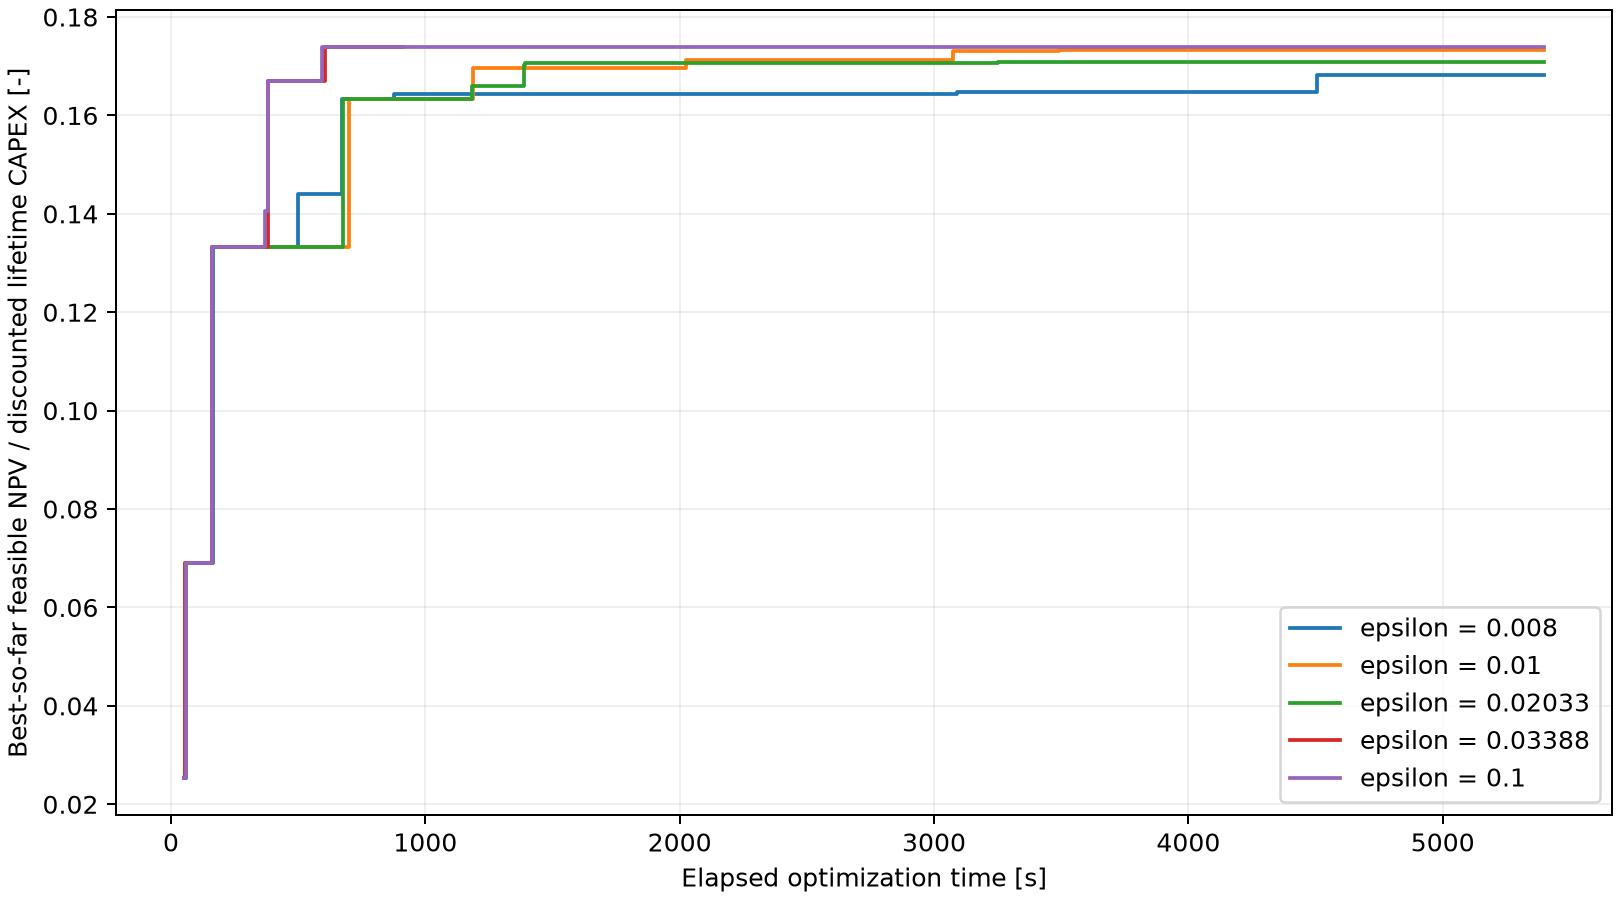

In [4]:
figure_folders = sorted(run_directory.glob('figures_*')) if run_directory is not None else []
if figure_folders:
    for name in ('capacity_distribution', 'financial_objective_convergence',
                 'joint_hpp_dc_sizing', 'cashflow', 'cumulative_discounted_cashflow'):
        image = figure_folders[-1] / (name + '.png')
        if image.exists():
            display(Image(filename=str(image)))
if batch_directory is not None:
    batch_figures = sorted(batch_directory.glob('figures_*'))
    if batch_figures:
        for name in ('financial_revenue_sensitivity', 'penalty_comparison',
                     'penalty_feasible_percentage', 'penalty_convergence'):
            image = batch_figures[-1] / (name + '.png')
            if image.exists():
                display(Image(filename=str(image)))
